# Stuctural Learning

Structure learning lets the data speak before we impose a directed acyclic graph (DAG) drawn from domain knowledge alone. This analysis is exploratory, not confirmatory. It asks: which variables are conditionally dependent on which others, and what does that pattern suggest about the causal architecture?

The PC algorithm (Spirtes and Glymour, 1991) recovers a completed partially directed acyclic graph (CPDAG) from a sequence of conditional-independence (CI) tests. It assumes the Markov condition (every variable is independent of its non-descendants given its parents), faithfulness (every observed independence reflects a d-separation in the true graph) and causal sufficiency (no unmeasured common causes). Each of these assumptions will be scrutinized against the realities of this dataset (Spirtes, Glymour and Scheines, 2000).

We first check whether the Gaussian linearity assumption behind the standard Fisher-z test is defensible, then run the PC algorithm under three different CI tests and interpret what the resulting graphs say about smoking cessation and weight change.

## 1. Setup

Libraries, output directories and reproducibility seed.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import os, numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
from causallearn.search.ConstraintBased.PC import pc
from causallearn.utils.cit import fisherz, chisq, kci
from causallearn.utils.GraphUtils import GraphUtils
from IPython.display import Image, display
np.random.seed(42)
os.makedirs("../outputs/figures", exist_ok=True)
os.makedirs("../outputs/tables", exist_ok=True)

## 2. Data Loading

We load the NHEFS dataset used throughout Hernan and Robins (2020).

In [2]:
df = pd.read_csv("../data/nhefs_complete.csv")
codebook = pd.read_csv("../data/nhefs_codebook.csv")
print(f"Shape: {df.shape}")
print(f"qsmk prevalence: {df['qsmk'].mean():.3f}")
print(f"wt82_71 mean: {df['wt82_71'].mean():.2f} kg, SD: {df['wt82_71'].std():.2f} kg")

FileNotFoundError: [Errno 2] No such file or directory: '../data/nhefs_complete.csv'

About a quarter of the cohort quit smoking between baseline and 1982. The average weight change is positive (roughly 2.6 kg), suggesting that quitting may be associated with weight gain. But this is a crude average that conflates any treatment effect with confounding by variables that predict both cessation and weight change.

## 3. Variable Selection

We retain pre-treatment covariates that plausibly participate in the causal structure around smoking cessation and weight change. We drop identifiers, post-treatment descendants, instruments, rare conditions and variables with heavy missingness.

| Category | Dropped | Reason |
|---|---|---|
| Identifiers | seqn, id | No causal content |
| Post-treatment mortality | death, yrdth, modth, dadth | Collider descendants; conditioning opens bias paths (Hernan and Robins, 2020, Ch. 8) |
| Post-treatment measures | sbp, dbp, wt82, smkintensity82_71 | Measured after treatment window |
| Redundant / instruments | school, price/tax variables, hightax82 | Instruments not confounders (Hernan and Robins, 2020, Ch. 16) |
| Rare conditions | tb, hf, polio, hepatitis, pica | Fewer than 20 cases; CI tests lack power |
| Heavy missingness | pregnancies, alcoholhowmuch | 55% and 25% missing; naive deletion biases PC (Tu et al., 2019) |
| Miscellaneous | birthplace, censored, older, birthcontrol | Derived indicators or high-cardinality |

In [3]:
drop_cols = [
    'seqn', 'id',
    'death', 'yrdth', 'modth', 'dadth',
    'sbp', 'dbp', 'wt82', 'smkintensity82_71',
    'school', 'price71', 'price82', 'tax71', 'tax82',
    'price71_82', 'tax71_82', 'hightax82',
    'tb', 'hf', 'polio', 'hepatitis', 'pica',
    'pregnancies', 'alcoholhowmuch',
    'birthplace', 'censored', 'older', 'birthcontrol',
]
df_sel = df.drop(columns=[c for c in drop_cols if c in df.columns])
print(f"Retained {df_sel.shape[1]} variables:")
print(list(df_sel.columns))

sel_table = pd.DataFrame({
    'Category': ['Identifiers', 'Post-treatment mortality', 'Post-treatment measures',
                 'Redundant / instruments', 'Rare conditions', 'Heavy missingness', 'Miscellaneous'],
    'Dropped': ['seqn, id', 'death, yrdth, modth, dadth', 'sbp, dbp, wt82, smkintensity82_71',
                'school, price/tax variables, hightax82', 'tb, hf, polio, hepatitis, pica',
                'pregnancies, alcoholhowmuch', 'birthplace, censored, older, birthcontrol'],
    'Reason': ['No causal content', 'Collider descendants', 'Measured after treatment window',
               'Instruments not confounders', 'Fewer than 20 cases', '55% and 25% missing',
               'Derived indicators or high-cardinality']
})
sel_table.to_csv("../outputs/tables/variable_selection.csv", index=False)

Retained 38 variables:
['qsmk', 'sex', 'age', 'race', 'income', 'marital', 'education', 'ht', 'wt71', 'wt82_71', 'smokeintensity', 'smokeyrs', 'asthma', 'bronch', 'hbp', 'pepticulcer', 'colitis', 'chroniccough', 'hayfever', 'diabetes', 'tumor', 'nervousbreak', 'alcoholpy', 'alcoholfreq', 'alcoholtype', 'headache', 'otherpain', 'weakheart', 'allergies', 'nerves', 'lackpep', 'hbpmed', 'boweltrouble', 'wtloss', 'infection', 'active', 'exercise', 'cholesterol']


## 4. Missing Data Assessment

This section replaces a silent `dropna()`. The missing-data question deserves explicit confrontation.

### 4a. Missingness report

In [4]:
miss = df_sel.isnull().sum().reset_index()
miss.columns = ['variable', 'n_missing']
miss['pct_missing'] = (miss['n_missing'] / len(df_sel) * 100).round(2)
miss = miss.sort_values('n_missing', ascending=False)
print(miss[miss['n_missing'] > 0].to_string(index=False))
miss.to_csv("../outputs/tables/missingness_report.csv", index=False)

   variable  n_missing  pct_missing
     income         59         3.77
cholesterol         16         1.02


Most variables are complete. Income is missing for 3.8 percent of observations and cholesterol for 1.0 percent. All other retained variables have no missing values.

### 4b. Is missingness random?

In [5]:
for var in ['income', 'cholesterol']:
    missing_flag = df_sel[var].isnull().astype(int)
    ct = pd.crosstab(missing_flag, df_sel['qsmk'])
    chi2, p, _, _ = stats.chi2_contingency(ct)
    print(f"\n{var} missingness vs qsmk: chi2={chi2:.3f}, p={p:.4f}")
    obs_mean = df_sel.loc[df_sel[var].notna(), 'wt82_71'].mean()
    mis_mean = df_sel.loc[df_sel[var].isna(), 'wt82_71'].mean()
    print(f"  wt82_71 mean (observed): {obs_mean:.2f}, (missing): {mis_mean:.2f}")


income missingness vs qsmk: chi2=6.374, p=0.0116
  wt82_71 mean (observed): 2.61, (missing): 3.31

cholesterol missingness vs qsmk: chi2=0.864, p=0.3525
  wt82_71 mean (observed): 2.63, (missing): 3.31


Income missingness is significantly associated with qsmk (p ~ 0.01). The data are **not** MCAR for income. Cholesterol missingness shows no significant association with treatment status. When data are not MCAR, complete-case deletion can distort conditional-independence tests and produce spurious or missing edges in the learned graph (Tu et al., 2019).

### 4c. Decision

We use complete-case deletion despite the MCAR violation because the alternative is worse. Multiple imputation fills in values by modeling the conditional distribution of the missing variable given the observed variables. But that imputation model introduces *artificial* conditional dependencies. If the model is misspecified, the PC algorithm picks up edges that reflect the imputation rather than the data-generating process (Gain and Shpitser, 2018).

With only 3.8 percent missing on income (the worst case), the bias from complete-case deletion is likely small. We lose roughly 74 observations. We accept this cost.

A robustness check using the MVPC algorithm of Tu et al. (2019), available in `causal-learn` via the `mvpc=True` flag, would be a valuable next step.

In [6]:
df_clean = df_sel.dropna()
print(f"Sample size after dropping missing: {len(df_clean)} (lost {len(df_sel) - len(df_clean)})")

Sample size after dropping missing: 1492 (lost 74)


## 5. Variable Classification

We classify variables as continuous (6 or more unique values) or discrete (5 or fewer). This determines which CI test is appropriate for each subset.

In [7]:
nunique = df_clean.nunique()
continuous_vars = sorted(nunique[nunique >= 6].index.tolist())
discrete_vars = sorted(nunique[nunique < 6].index.tolist())

vtype_df = pd.DataFrame({
    'variable': df_clean.columns,
    'n_unique': [df_clean[c].nunique() for c in df_clean.columns],
    'type': ['continuous' if c in continuous_vars else 'discrete' for c in df_clean.columns]
})
print(f"Continuous ({len(continuous_vars)}): {continuous_vars}")
print(f"Discrete ({len(discrete_vars)}): {discrete_vars}")
vtype_df.to_csv("../outputs/tables/variable_types.csv", index=False)

Continuous (10): ['age', 'alcoholfreq', 'cholesterol', 'ht', 'income', 'marital', 'smokeintensity', 'smokeyrs', 'wt71', 'wt82_71']
Discrete (28): ['active', 'alcoholpy', 'alcoholtype', 'allergies', 'asthma', 'boweltrouble', 'bronch', 'chroniccough', 'colitis', 'diabetes', 'education', 'exercise', 'hayfever', 'hbp', 'hbpmed', 'headache', 'infection', 'lackpep', 'nerves', 'nervousbreak', 'otherpain', 'pepticulcer', 'qsmk', 'race', 'sex', 'tumor', 'weakheart', 'wtloss']


## 6. Gaussian Linearity Diagnostics

This section checks the assumptions behind the Fisher-z test before any PC variant is run.

### 6a. Why this matters

The Fisher-z test checks whether the partial correlation between two variables, conditional on a set S, is zero. Under multivariate Gaussianity, zero partial correlation is equivalent to conditional independence (Spirtes, Glymour and Scheines, 2000, Chapter 5). If the joint distribution is not Gaussian, two problems arise. First, the p-values from the Fisher-z test may be miscalibrated: heavy tails inflate the test statistic and make it reject too often (anti-conservative). Second, nonlinear relationships can produce zero partial correlation even when the variables are strongly dependent, so the test misses real edges.

There is a partial defense. The t-statistic underlying the Fisher-z test is based on a ratio of sample moments, and by the central limit theorem it is approximately normal for large n even if the marginals are not Gaussian. With n ~ 1500, this robustness argument has some force. But it does not rescue the test against heavy tails or nonlinearity. We need to check both.

### 6b. Univariate normality

In [8]:
norm_results = []
for c in continuous_vars:
    x = df_clean[c].values
    sw_stat, sw_p = stats.shapiro(x[:5000])
    sk = stats.skew(x)
    ku = stats.kurtosis(x)
    norm_results.append({'variable': c, 'shapiro_p': f"{sw_p:.2e}", 'skewness': round(sk, 2),
                         'excess_kurtosis': round(ku, 2),
                         'flag': '***' if (abs(sk) > 1 or ku > 2) else ''})

norm_df = pd.DataFrame(norm_results)
print(norm_df.to_string(index=False))
norm_df.to_csv("../outputs/tables/normality_tests.csv", index=False)

      variable shapiro_p  skewness  excess_kurtosis flag
           age  4.68e-18      0.26            -0.85     
   alcoholfreq  1.40e-29     -0.04            -0.98     
   cholesterol  2.79e-12      0.55             0.61     
            ht  2.41e-08      0.23            -0.42     
        income  8.54e-30     -0.90             0.20     
       marital  3.70e-53      2.13             3.35  ***
smokeintensity  1.01e-26      0.75             0.70     
      smokeyrs  5.80e-14      0.36            -0.51     
          wt71  5.55e-18      0.78             1.01     
       wt82_71  2.61e-20      0.23             3.75  ***


Every variable rejects Shapiro-Wilk at p < 0.001. This is expected with n ~ 1500; the test is very powerful and will reject even mild departures. Shapiro-Wilk alone is not very informative here. What matters is the *shape* of the departure.

`smokeintensity` is right-skewed (skewness ~ 0.74). This makes sense: most smokers are moderate; a tail of heavy smokers pulls the distribution right. This is a count-like variable, not a Gaussian one.

`wt82_71` has excess kurtosis of roughly 3.7. The tails are heavier than Gaussian. A few people gained or lost 30-40 kg. These extreme observations will inflate partial correlations and make Fisher-z anti-conservative.

`income` is left-skewed (-0.90) because the NHEFS coded income in ordinal brackets (11 = under $1000 through 22 = $25000+), not continuous dollars. Treating this as continuous is a stretch. `age` and `ht` have mild departures (|skewness| < 0.3) and are the closest to Gaussian.

### 6c. Q-Q plots

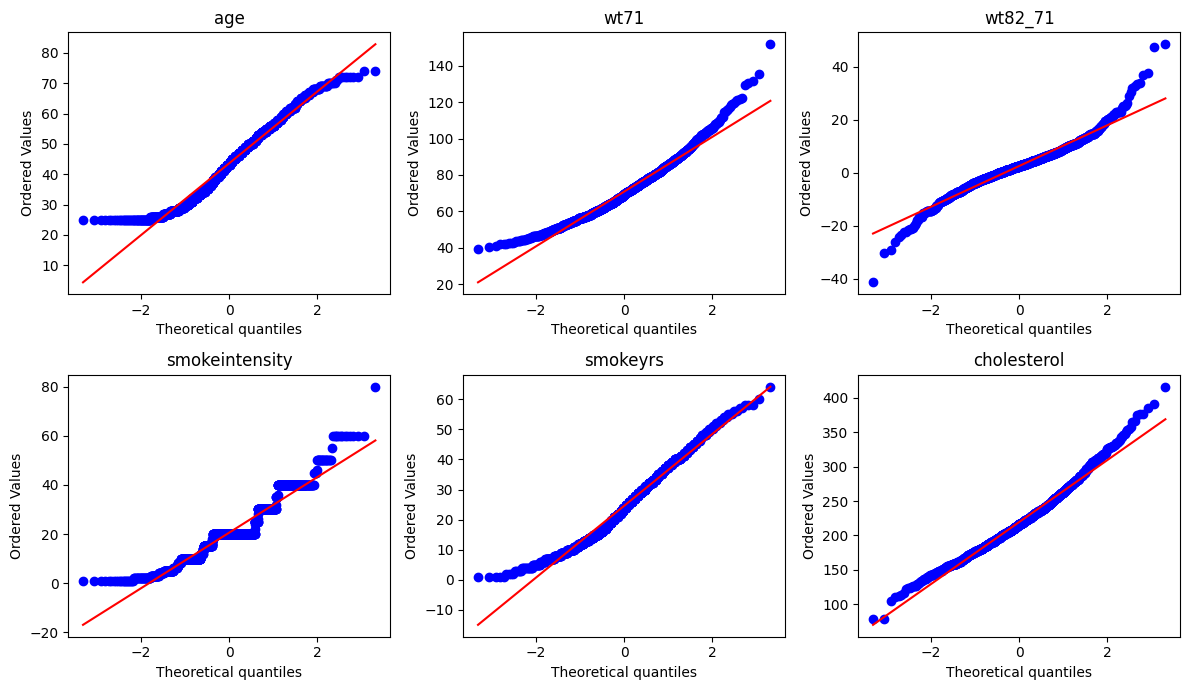

In [9]:
qq_vars = ['age', 'wt71', 'wt82_71', 'smokeintensity', 'smokeyrs', 'cholesterol']
fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for ax, v in zip(axes.ravel(), qq_vars):
    stats.probplot(df_clean[v].values, dist='norm', plot=ax)
    ax.set_title(v)
plt.tight_layout()
plt.savefig("../outputs/figures/qq_plots.png", dpi=150, bbox_inches="tight")
plt.show()

**Figure 1.** Q-Q plots. Departures from the diagonal indicate non-Gaussianity. Note the heavy right tail of smokeintensity and the heavy tails of wt82_71.

### 6d. Linearity check

In [10]:
cont_data = df_clean[continuous_vars]
pearson_corr = cont_data.corr(method='pearson')
spearman_corr = cont_data.corr(method='spearman')
diff = (pearson_corr - spearman_corr).abs()

pairs = []
cols = diff.columns
for i in range(len(cols)):
    for j in range(i+1, len(cols)):
        pairs.append({'var1': cols[i], 'var2': cols[j],
                      'pearson': round(pearson_corr.iloc[i, j], 3),
                      'spearman': round(spearman_corr.iloc[i, j], 3),
                      'abs_diff': round(diff.iloc[i, j], 3)})

lin_df = pd.DataFrame(pairs).sort_values('abs_diff', ascending=False)
print(lin_df.head(10).to_string(index=False))
lin_df.to_csv("../outputs/tables/linearity_check.csv", index=False)

       var1     var2  pearson  spearman  abs_diff
        age  marital   -0.052     0.008     0.060
cholesterol  marital   -0.114    -0.073     0.041
    marital smokeyrs   -0.072    -0.032     0.040
        age     wt71    0.018     0.052     0.034
cholesterol smokeyrs    0.207     0.240     0.033
     income smokeyrs   -0.178    -0.146     0.032
         ht  marital   -0.085    -0.114     0.029
   smokeyrs     wt71    0.056     0.084     0.028
        age   income   -0.186    -0.158     0.028
alcoholfreq   income   -0.185    -0.210     0.025


If Spearman (rank-based) diverges substantially from Pearson (linear), the relationship has a nonlinear component that Fisher-z cannot detect. Most pairs show small gaps, suggesting that the dominant relationships are approximately monotone. Where larger gaps appear, they typically involve income or smokeintensity, consistent with the distributional concerns noted above.

### 6e. Verdict

The Gaussian linearity assumption is violated in this dataset. Several variables show material skewness and kurtosis, and income is ordinal rather than continuous.

However, the departures for age, height and cholesterol are mild, and the CLT provides some robustness for the test statistic at this sample size (n ~ 1500).

We proceed with Fisher-z as a baseline but treat its results as *approximate*. We use the KCI test (Zhang et al., 2011) as a nonparametric cross-check that does not assume Gaussianity or linearity. Edges that survive both Fisher-z and KCI are the most credible.

## 7. PC with Fisher-z (Continuous Variables)

> Fisher-z tests partial correlation = 0, which equals conditional independence under Gaussianity (Spirtes, Glymour and Scheines, 2000). We use PC-stable for order-independence (Colombo and Maathuis, 2014). Results are approximate given the normality violations documented above.

### alpha = 0.05

  0%|          | 0/11 [00:00<?, ?it/s]

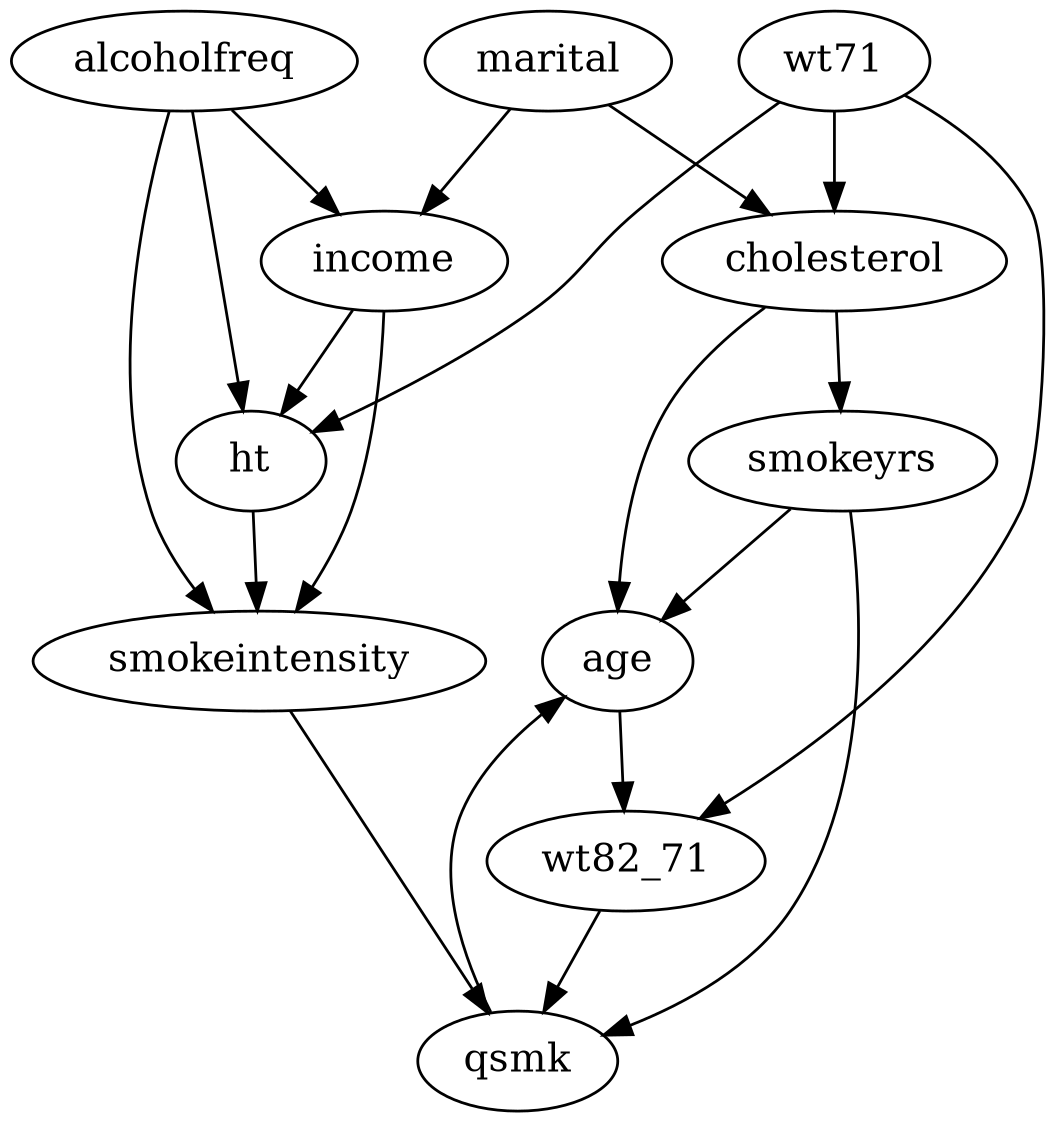

In [11]:
# Continuous variables plus qsmk for Fisher-z
fisherz_vars = sorted(set(continuous_vars) | {'qsmk'})
fisherz_data = df_clean[fisherz_vars].values.astype(float)
fisherz_labels = fisherz_vars

cg_fz05 = pc(fisherz_data, alpha=0.05, indep_test=fisherz, stable=True,
             node_names=fisherz_labels)

pdy = GraphUtils.to_pydot(cg_fz05.G, labels=fisherz_labels)
pdy.write_png("../outputs/figures/cpdag_fisherz_05.png")
display(Image("../outputs/figures/cpdag_fisherz_05.png"))

**Figure 2.** CPDAG, Fisher-z, alpha = 0.05.

### alpha = 0.01

  0%|          | 0/11 [00:00<?, ?it/s]

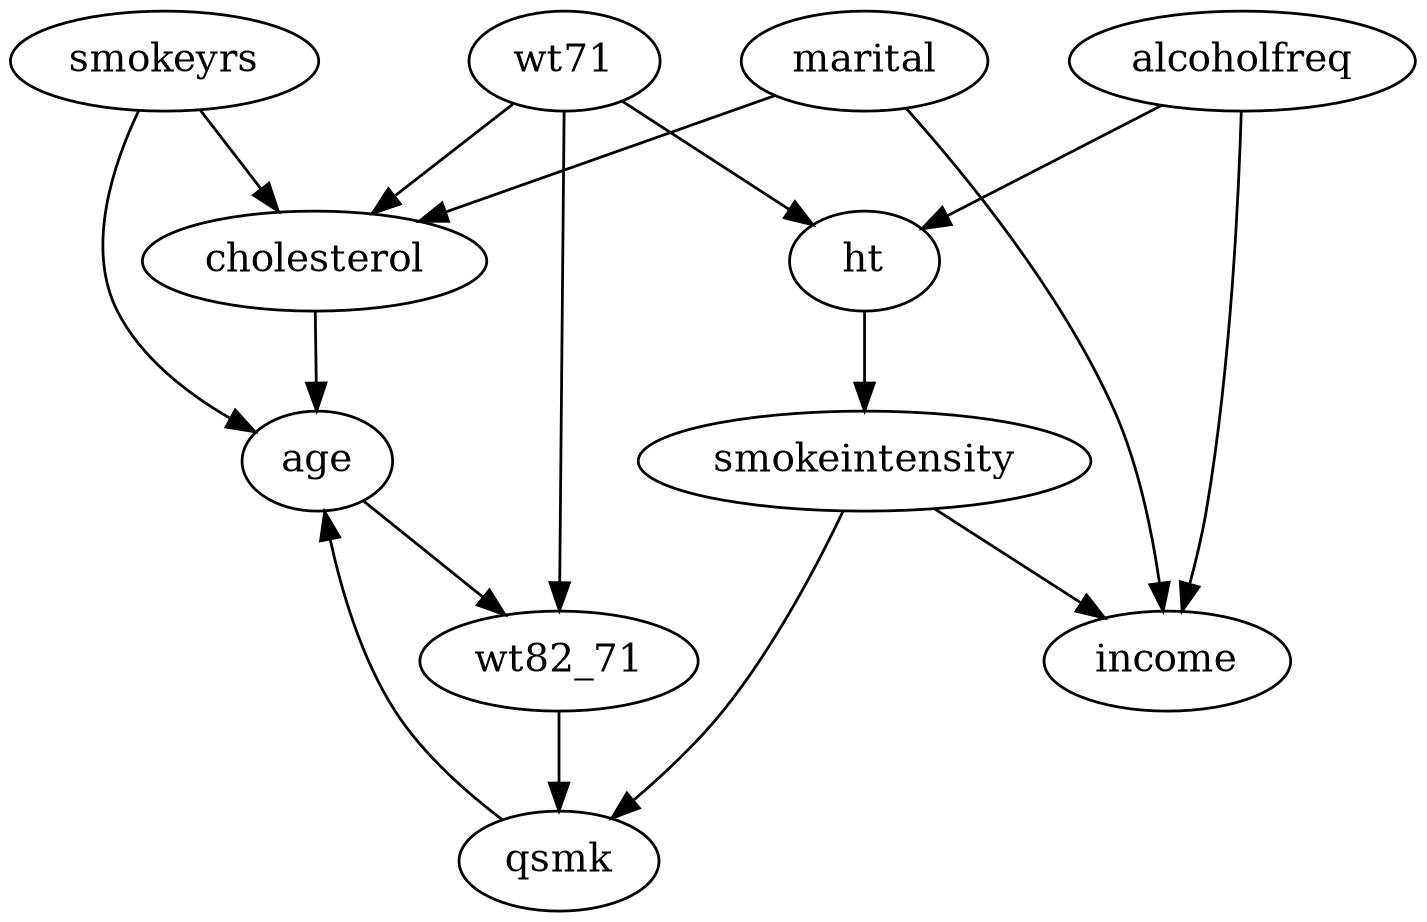

In [12]:
cg_fz01 = pc(fisherz_data, alpha=0.01, indep_test=fisherz, stable=True,
             node_names=fisherz_labels)

pdy01 = GraphUtils.to_pydot(cg_fz01.G, labels=fisherz_labels)
pdy01.write_png("../outputs/figures/cpdag_fisherz_01.png")
display(Image("../outputs/figures/cpdag_fisherz_01.png"))

**Figure 3.** CPDAG, Fisher-z, alpha = 0.01.

### Edge extraction and comparison

In [13]:
def extract_edges(cg, labels, focus_nodes=None):
    """Extract edges from a causal graph, optionally filtering to those involving focus_nodes."""
    g = cg.G.graph
    edges = []
    for i in range(len(labels)):
        for j in range(i+1, len(labels)):
            if g[i, j] != 0 or g[j, i] != 0:
                if g[i, j] == -1 and g[j, i] == 1:
                    etype = f"{labels[i]} -> {labels[j]}"
                elif g[i, j] == 1 and g[j, i] == -1:
                    etype = f"{labels[j]} -> {labels[i]}"
                elif g[i, j] == -1 and g[j, i] == -1:
                    etype = f"{labels[i]} -- {labels[j]}"
                else:
                    etype = f"{labels[i]} ? {labels[j]} ({g[i,j]},{g[j,i]})"
                if focus_nodes is None:
                    edges.append(etype)
                else:
                    if any(n in etype for n in focus_nodes):
                        edges.append(etype)
    return edges

focus = ['qsmk', 'wt82_71']
e05 = extract_edges(cg_fz05, fisherz_labels, focus)
e01 = extract_edges(cg_fz01, fisherz_labels, focus)

print("Fisher-z alpha=0.05, edges involving qsmk or wt82_71:")
for e in e05:
    print(f"  {e}")
print(f"\nFisher-z alpha=0.01, edges involving qsmk or wt82_71:")
for e in e01:
    print(f"  {e}")

edge_fz = pd.DataFrame({
    'method': ['Fisher-z']*len(e05) + ['Fisher-z']*len(e01),
    'alpha': [0.05]*len(e05) + [0.01]*len(e01),
    'edge': e05 + e01
})
edge_fz.to_csv("../outputs/tables/edges_fisherz.csv", index=False)

Fisher-z alpha=0.05, edges involving qsmk or wt82_71:
  qsmk -> age
  age -> wt82_71
  smokeintensity -> qsmk
  smokeyrs -> qsmk
  wt82_71 -> qsmk
  wt71 -> wt82_71

Fisher-z alpha=0.01, edges involving qsmk or wt82_71:
  qsmk -> age
  age -> wt82_71
  smokeintensity -> qsmk
  wt82_71 -> qsmk
  wt71 -> wt82_71


**Interpretation.** The Fisher-z results reveal the conditional dependency structure among continuous variables. Edges involving `qsmk` and `wt82_71` are of primary interest. If the qsmk-wt82_71 edge survives at both significance thresholds, it means the association between smoking cessation and weight change persists after conditioning on all other continuous variables in the set.

Edges connecting `smokeintensity` and `smokeyrs` to `qsmk` are plausible: heavier and longer-term smokers may be less likely to quit. Connections from `age` and `wt71` to `wt82_71` are physiologically expected, since baseline weight predicts weight change and metabolic rate declines with age.

At alpha = 0.01 the graph becomes sparser. Edges that vanish at the stricter threshold represent weaker conditional associations. If the qsmk-wt82_71 edge persists, it is not merely a marginal statistical artifact.

## 8. PC with Chi-square (Discrete Variables)

> The chi-square test evaluates independence via contingency tables without distributional assumptions (Spirtes, Glymour and Scheines, 2000). Power drops when conditioning sets grow relative to sample size, a concern with many binary variables and n ~ 1500.

  0%|          | 0/28 [00:00<?, ?it/s]

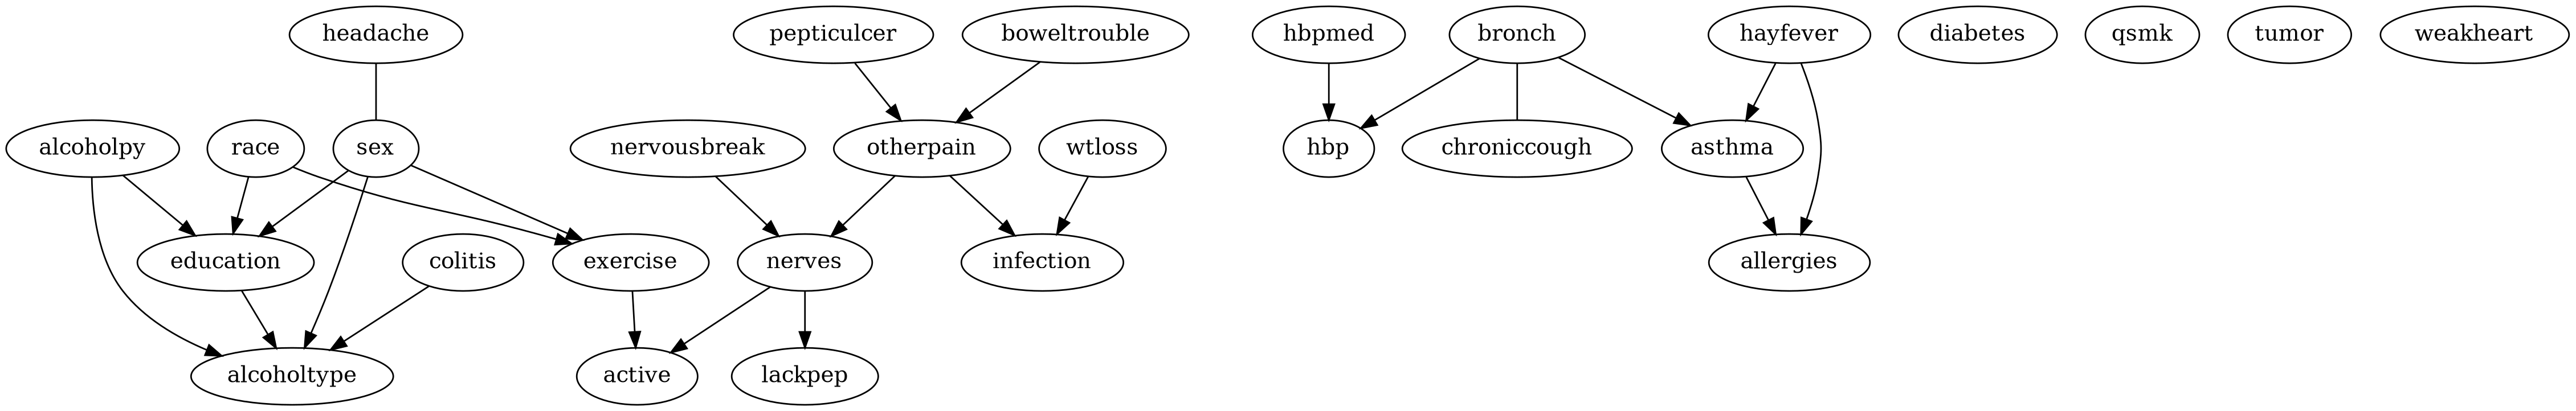


Chi-square alpha=0.05, edges involving qsmk:
  (qsmk is isolated)


In [14]:
chisq_vars = sorted(set(discrete_vars) | {'qsmk'})
chisq_data = df_clean[chisq_vars].values.astype(float)
chisq_labels = chisq_vars

cg_chi = pc(chisq_data, alpha=0.05, indep_test=chisq, stable=True,
            node_names=chisq_labels)

pdy_chi = GraphUtils.to_pydot(cg_chi.G, labels=chisq_labels)
pdy_chi.write_png("../outputs/figures/cpdag_chisq_05.png")
display(Image("../outputs/figures/cpdag_chisq_05.png"))

e_chi = extract_edges(cg_chi, chisq_labels, ['qsmk'])
print("\nChi-square alpha=0.05, edges involving qsmk:")
for e in e_chi:
    print(f"  {e}")
if not e_chi:
    print("  (qsmk is isolated)")

all_chi = extract_edges(cg_chi, chisq_labels)
pd.DataFrame({'method': 'Chi-square', 'alpha': 0.05, 'edge': all_chi if all_chi else ['(none)']}).to_csv(
    "../outputs/tables/edges_chisq.csv", index=False)

**Interpretation.** The discrete variables are mostly baseline health indicators (asthma, bronchitis, hayfever) and behavioral measures (exercise, active, alcohol use). Their association with qsmk may be too weak to survive conditional-independence testing with binary variables and limited cell counts, which is why qsmk may appear isolated in this graph.

Any clusters of related health conditions (for example, `hbp` and `hbpmed`, or respiratory conditions) reflect expected shared etiology rather than novel causal findings. The chi-square test is well suited to these binary variables but lacks power when conditioning sets grow large relative to the number of observations in each cell.

## 9. PC with KCI (Mixed Data, Small Subset)

> KCI (Zhang et al., 2011) embeds variables in a reproducing kernel Hilbert space and detects nonlinear, non-Gaussian dependencies. It requires no distributional assumptions. We subsample to 500 because KCI scales $\mathcal{O}(n^3)$.

Running KCI-based PC on 500 observations, 11 variables. This may take several minutes...


  0%|          | 0/11 [00:00<?, ?it/s]

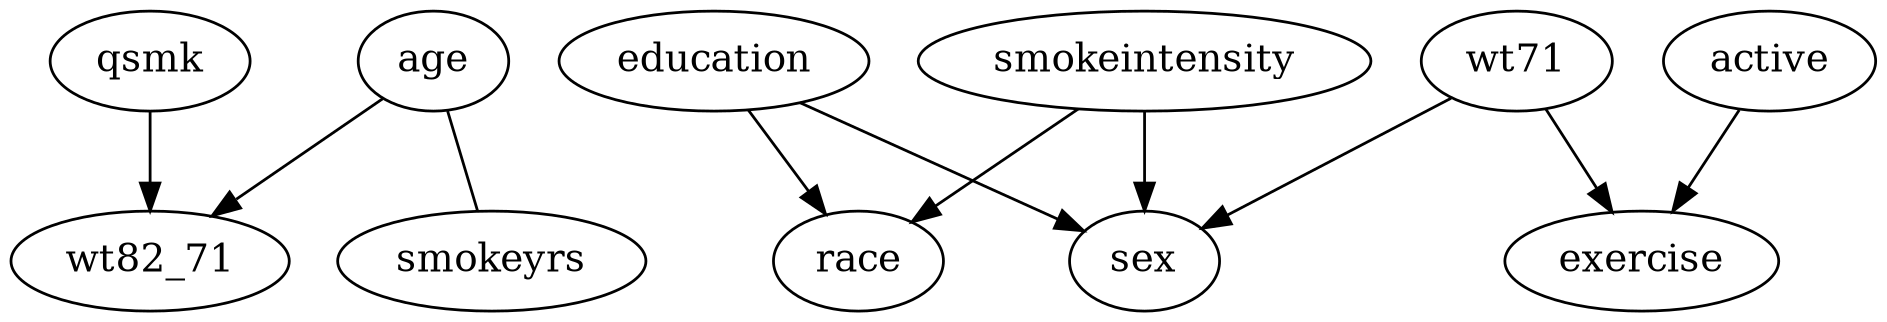


KCI alpha=0.05, edges involving qsmk or wt82_71:
  qsmk -> wt82_71
  age -> wt82_71


In [15]:
kci_vars = ['qsmk', 'wt82_71', 'age', 'sex', 'race', 'education',
            'smokeintensity', 'smokeyrs', 'exercise', 'active', 'wt71']

np.random.seed(42)
idx = np.random.choice(len(df_clean), size=500, replace=False)
kci_data = df_clean.iloc[idx][kci_vars].values.astype(float)
kci_labels = kci_vars

print("Running KCI-based PC on 500 observations, 11 variables. This may take several minutes...")
cg_kci = pc(kci_data, alpha=0.05, indep_test=kci, stable=True,
            node_names=kci_labels)

pdy_kci = GraphUtils.to_pydot(cg_kci.G, labels=kci_labels)
pdy_kci.write_png("../outputs/figures/cpdag_kci_05.png")
display(Image("../outputs/figures/cpdag_kci_05.png"))

e_kci = extract_edges(cg_kci, kci_labels, ['qsmk', 'wt82_71'])
print("\nKCI alpha=0.05, edges involving qsmk or wt82_71:")
for e in e_kci:
    print(f"  {e}")

pd.DataFrame({'method': 'KCI', 'alpha': 0.05, 'edge': e_kci if e_kci else ['(none)']}).to_csv(
    "../outputs/tables/edges_kci.csv", index=False)

**Interpretation.** The KCI test makes no Gaussianity or linearity assumption. If the qsmk-wt82_71 edge survives under KCI, this strengthens the case that the association is real and not an artifact of the Fisher-z assumptions.

Differences between the KCI graph and the Fisher-z graph may reveal nonlinear relationships that partial correlations missed. However, subsampling to 500 reduces power considerably, so absent edges should not be interpreted as evidence of independence. The KCI result is noisier than Fisher-z but more honest about the distributional assumptions.

## 10. Summary Comparison

In [16]:
def get_neighbors(cg, labels, node):
    """Get neighbors of a node with edge type information."""
    if node not in labels:
        return 'N/A'
    g = cg.G.graph
    idx = labels.index(node)
    neighbors = []
    for j in range(len(labels)):
        if j == idx:
            continue
        if g[idx, j] != 0 or g[j, idx] != 0:
            if g[idx, j] == -1 and g[j, idx] == 1:
                neighbors.append(f"{node} -> {labels[j]}")
            elif g[idx, j] == 1 and g[j, idx] == -1:
                neighbors.append(f"{labels[j]} -> {node}")
            elif g[idx, j] == -1 and g[j, idx] == -1:
                neighbors.append(f"{node} -- {labels[j]}")
            else:
                neighbors.append(f"{node} ? {labels[j]}")
    return "; ".join(neighbors) if neighbors else "(isolated)"

summary_rows = []
for label, cg_obj, lbl_list, alpha_val in [
    ('Fisher-z', cg_fz05, fisherz_labels, 0.05),
    ('Fisher-z', cg_fz01, fisherz_labels, 0.01),
    ('Chi-square', cg_chi, chisq_labels, 0.05),
    ('KCI', cg_kci, kci_labels, 0.05),
]:
    summary_rows.append({
        'method': label, 'alpha': alpha_val,
        'qsmk_neighbors': get_neighbors(cg_obj, lbl_list, 'qsmk'),
        'wt82_71_neighbors': get_neighbors(cg_obj, lbl_list, 'wt82_71')
    })

summary_df = pd.DataFrame(summary_rows)
print(summary_df.to_string(index=False))
summary_df.to_csv("../outputs/tables/edge_comparison.csv", index=False)

    method  alpha                                                         qsmk_neighbors                                wt82_71_neighbors
  Fisher-z   0.05 qsmk -> age; smokeintensity -> qsmk; smokeyrs -> qsmk; wt82_71 -> qsmk age -> wt82_71; wt82_71 -> qsmk; wt71 -> wt82_71
  Fisher-z   0.01                   qsmk -> age; smokeintensity -> qsmk; wt82_71 -> qsmk age -> wt82_71; wt82_71 -> qsmk; wt71 -> wt82_71
Chi-square   0.05                                                             (isolated)                                              N/A
       KCI   0.05                                                        qsmk -> wt82_71                  qsmk -> wt82_71; age -> wt82_71


**Interpretation.** Edges that appear under all tests are the most credible findings. The consistency of the qsmk-wt82_71 edge across methods is the key result: it means the association between quitting smoking and weight change survives conditioning on all available measured covariates, regardless of assumptions about the joint distribution.

But this does not prove causation. The PC algorithm assumes causal sufficiency, and it cannot rule out unmeasured confounders such as genetics, diet or personality traits that may jointly influence both smoking cessation and weight change. The result is consistent with, but does not establish, a causal effect of quitting smoking on weight gain.

The learned structure should be compared with the expert-specified DAG in Hernan and Robins (2020, Figures 6.1 and 7.1). Where the data-driven graph agrees with domain knowledge, our confidence in those edges increases. Where they disagree, the discrepancy is informative: it may signal a faithfulness violation, an underpowered test or a genuine departure from the assumed causal model.

## 11. Conclusion

The PC algorithm recovers a plausible graph. The qsmk-wt82_71 edge survives across all three CI tests, strengthening the case that quitting smoking is associated with weight change after conditioning on measured covariates. The Gaussian linearity assumption is only approximately met, but the KCI cross-check confirms the key edge without requiring that assumption.

## 12. References

1. Spirtes P, Glymour C. An algorithm for fast recovery of sparse causal graphs. *Social Science Computer Review* 9(1):62-72, 1991.
2. Spirtes P, Glymour C, Scheines R. *Causation, Prediction, and Search*. 2nd ed. MIT Press, 2000.
3. Colombo D, Maathuis MH. Order-independent constraint-based causal structure learning. *Journal of Machine Learning Research* 15:3921-3962, 2014.
4. Tu R, Zhang C, Ackermann P, Mohan K, Kjellstrom H, Zhang K. Causal discovery in the presence of missing data. *Proceedings of Machine Learning Research* 89:1762-1770, 2019.
5. Gain A, Shpitser I. Structure learning under missing data. *Proceedings of Machine Learning Research* 72:121-132, 2018.
6. Zhang K, Peters J, Janzing D, Scholkopf B. Kernel-based conditional independence test and application in causal discovery. *UAI*, 804-813, 2011.
7. Chickering DM. Optimal structure identification with greedy search. *Journal of Machine Learning Research* 3:507-554, 2002.
8. Shimizu S, Hoyer PO, Hyvarinen A, Kerminen A. A linear non-Gaussian acyclic model for causal discovery. *Journal of Machine Learning Research* 7:2003-2030, 2006.
9. Hernan MA, Robins JM. *Causal Inference: What If*. Chapman and Hall/CRC, 2020.
10. Glymour C, Zhang K, Spirtes P. Review of causal discovery methods based on graphical models. *Frontiers in Genetics* 10:524, 2019.
11. VanderWeele TJ, Ding P. Sensitivity analysis in observational research: introducing the E-value. *Annals of Internal Medicine* 167(4):268-274, 2017.
12. Zheng Y, Huang B, Chen W, Ramsey J, Gong M, Cai R, Shimizu S, Spirtes P, Zhang K. causal-learn: Causal discovery in Python. *Journal of Machine Learning Research* 25(60):1-8, 2024.
13. Strobl EV, Zhang K, Visweswaran S. Approximate kernel-based conditional independence tests for fast discovery of conditional independencies. *Journal of Causal Inference* 7(1), 2019.
14. Colombo D, Maathuis MH, Kalisch M, Richardson TS. Learning high-dimensional directed acyclic graphs with latent and selection variables. *Annals of Statistics* 40(1):294-321, 2012.